# 2. Features and labels

One row per encounter. Every feature uses only records dated **at or before** the encounter start;
the labels look at the 30 days **after** it. `tests/test_features.py` proves the first part by deleting
all later records and checking that no feature changes.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.figsize": (8, 4), "axes.spines.top": False, "axes.spines.right": False})

In [2]:
from workflow_ml.config import LABELS
from workflow_ml.features import feature_columns, load_table

table = load_table()
features = feature_columns(table)
print(f"{len(table):,} encounters, {table['patient_id'].nunique():,} patients, {len(features)} features")
table.head(3)

53,346 encounters, 1,171 patients, 589 features


,encounter_id,patient_id,t,age,male,year,n_previous,enc_class,prev1_enc_class,prev2_enc_class,...,now_careplans_mental_health_care_plan,now_careplans_dialysis_care_plan_record_artifa,now_careplans_major_depressive_disorder_clinic,now_careplans_spinal_cord_injury_rehabilitatio,now_n_observations,now_n_immunizations,medical_exam,lab_test,imaging,instrument_test
0,6b5bfe89-1c58-42e8-87c4-847b542d5f0b,00185faa-2760-4218-9bf5-db301acf8274,2010-11-09 15:06:37+00:00,6.976044,1.0,2010.0,0.0,5,-1,-1,...,0.0,0.0,0.0,0.0,10.0,1.0,0,0,0,0
1,e0a65c0f-fa38-46aa-bd00-60f4473230e2,00185faa-2760-4218-9bf5-db301acf8274,2011-11-15 15:06:37+00:00,7.991786,1.0,2011.0,1.0,5,5,-1,...,0.0,0.0,0.0,0.0,10.0,1.0,0,0,0,0
2,187f0326-5342-4b78-8818-db5418f9300b,00185faa-2760-4218-9bf5-db301acf8274,2012-08-03 15:06:37+00:00,8.709104,1.0,2012.0,2.0,0,5,5,...,0.0,0.0,0.0,0.0,1.0,0.0,0,0,0,0


## Feature groups

| Prefix | Meaning |
| --- | --- |
| `since_` | days since the last event of that kind |
| `gap_`, `gap2_` | days between the last two (and the two before) events |
| `due_` | `gap - since`: days left until the next event if the rhythm repeats |
| `count_` | how many such events so far |
| `*_last_30d/90d/365d` | events in a recent window |
| `active_` | days a condition has been active |
| `rate_` | share of the patient's earlier encounters (all / same type / same reason) that were followed by each workflow |
| `now_` | what was recorded at this encounter |

In [3]:
groups = pd.Series([name.split("_")[0] for name in features]).value_counts()
groups.to_frame("number of features").T

,now,since,due,gap,gap2,count,active,rate,same,encounter,...,lab,imaging,instrument,resolved,enc,age,male,year,n,reason
number of features,162,65,65,65,65,65,45,12,6,5,...,3,3,3,3,2,1,1,1,1,1


## Why schedule features work
The chance of a medical exam in the next 30 days jumps when the next wellness visit is *due*.

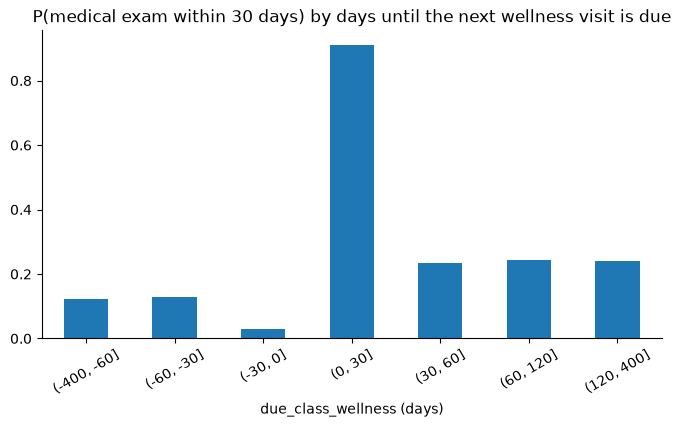

In [4]:
due = pd.cut(table["due_class_wellness"], [-400, -60, -30, 0, 30, 60, 120, 400])
table.groupby(due, observed=True)["medical_exam"].mean().plot.bar(
    rot=30, title="P(medical exam within 30 days) by days until the next wellness visit is due")
plt.xlabel("due_class_wellness (days)");

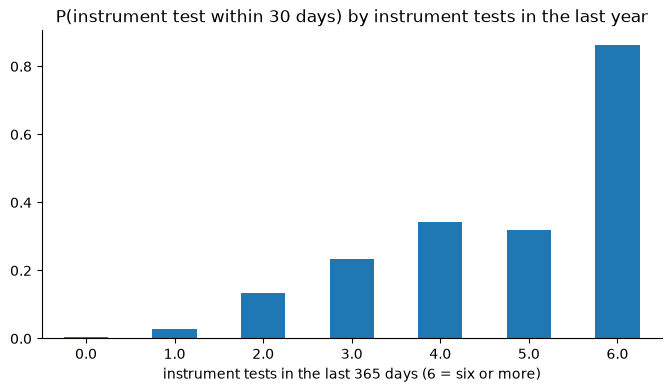

In [5]:
recent = table["instrument_test_last_365d"].clip(upper=6)
table.groupby(recent)["instrument_test"].mean().plot.bar(
    rot=0, title="P(instrument test within 30 days) by instrument tests in the last year")
plt.xlabel("instrument tests in the last 365 days (6 = six or more)");